# NeuroVascNet: current results

All numbers are read from `analysis_p2_p4/results/`. Rules and history: `FINAL_PLAN.md`, `TEST_LEDGER.md`.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import HTML, Image, display
from scipy import stats

R, FIG = Path("analysis_p2_p4/results"), Path("paper/figures")
J = lambda f: json.loads((R / f).read_text())
COH = {"hbci": "hBCI", "mental_workload": "Mental workload", "finemi": "FineMI"}
ci = lambda a, b: f"[{a:+.3f}, {b:+.3f}]"
def table(rows, cols=None):
    display(HTML(pd.DataFrame(rows, columns=cols).to_html(index=False, escape=False)))
def fig(name, w=620):
    display(Image(filename=str(FIG / f"{name}.png"), width=w))
def signflip(d, n=200000, seed=0):
    d, g = np.asarray(d), np.random.default_rng(seed)
    return (np.sum((g.choice([-1, 1], size=(n, len(d))) * d).mean(1) >= d.mean()) + 1) / (n + 1)
def spearman_p(rho, n):
    return 2 * stats.t.sf(abs(rho) * np.sqrt((n - 2) / (1 - rho ** 2)), n - 2)


## Scorecard

In [2]:
c1m, c1f = J("claim1_fresh_mental_workload_results.json"), J("claim1_fresh_finemi_results.json")
ext = J("external_claim2_results.json")["hbci_to_mental_workload"]
t2, bp, sm = J("nvc_transfer2_results.json"), J("nvc_bandpower_results.json"), J("nvc_delay_smooth_results.json")
rep = J("downstream_repr_nlab0_results.json")["hbci_MI_left_right (primary)"]["mean_acc"]
rel = J("calib_reliability_results.json")
cal = t2["calibrated | finemi"]
table([
 ["1. Shared fNIRS + fMRI space", f"fNIRS MW {c1m['fnirs']['joint']['r_subject']:.3f}, FineMI {c1f['fnirs']['joint']['r_subject']:.3f}; fMRI {c1m['fmri']['joint']['r_subject']:.3f}", "<b>Holds</b> (shared-space form). fMRI supervision does not improve fNIRS."],
 ["2. External validation", f"Same lab {ext['r_subject']:+.3f} {ci(ext['ci_low'], ext['ci_high'])}; other lab, calibrated {cal['diff']:+.3f} {ci(*cal['ci'])}", "<b>Holds within lab.</b> Cross-lab: frozen fails, calibrated nominal only."],
 ["3. Delay / coupling", f"hBCI {bp['hbci']['frac_beating_null']:.0%} beat null, delay {bp['hbci']['median_delay_s']:+.0f} s (EEG first); delay repeats {sm['hbci | raw']['agree_2s']:.0%} vs {sm['hbci | raw']['chance']:.0%} chance", "<b>Holds in hBCI.</b> Kernel shape repeats in other cohorts; precise delay does not."],
 ["4. Downstream EEG-only task", f"Virtual haemodynamics {rep['V']:.3f} vs PCA {rep['PC']:.3f}", "<b>Refuted.</b>"],
 ["5. Calibrated reliability", "Spearman " + ", ".join(f"{COH[c]} {rel[c]['spearman_score_vs_minus_error']:.2f}" for c in COH), "<b>Holds per person</b>; fails per trial."],
], ["Claim", "Best result", "Verdict"])

Claim,Best result,Verdict
1. Shared fNIRS + fMRI space,"fNIRS MW 0.123, FineMI 0.180; fMRI 0.068",Holds (shared-space form). fMRI supervision does not improve fNIRS.
2. External validation,"Same lab +0.205 [+0.128, +0.285]; other lab, calibrated +0.020 [+0.004, +0.039]","Holds within lab. Cross-lab: frozen fails, calibrated nominal only."
3. Delay / coupling,"hBCI 100% beat null, delay +6 s (EEG first); delay repeats 66% vs 29% chance",Holds in hBCI. Kernel shape repeats in other cohorts; precise delay does not.
4. Downstream EEG-only task,Virtual haemodynamics 0.697 vs PCA 0.760,Refuted.
5. Calibrated reliability,"Spearman hBCI 0.68, Mental workload 0.56, FineMI 0.90",Holds per person; fails per trial.


## Founding result: the information is infra-slow

Cohort,Slow EEG < 0.5 Hz,Band power 1–45 Hz,EOG,Local HbO,Person identification
"hBCI (FINAL_PLAN T1, T2, T3)",0.197 (ridge); 0.155 (deep),≈0.02,14% of all-EEG score,0.07–0.08,93%
Mental workload,"0.135 [+0.089, +0.183]",0.006,0.001,0.096,62%
FineMI,"0.203 [+0.164, +0.248]",0.045,-0.008,0.159,83%


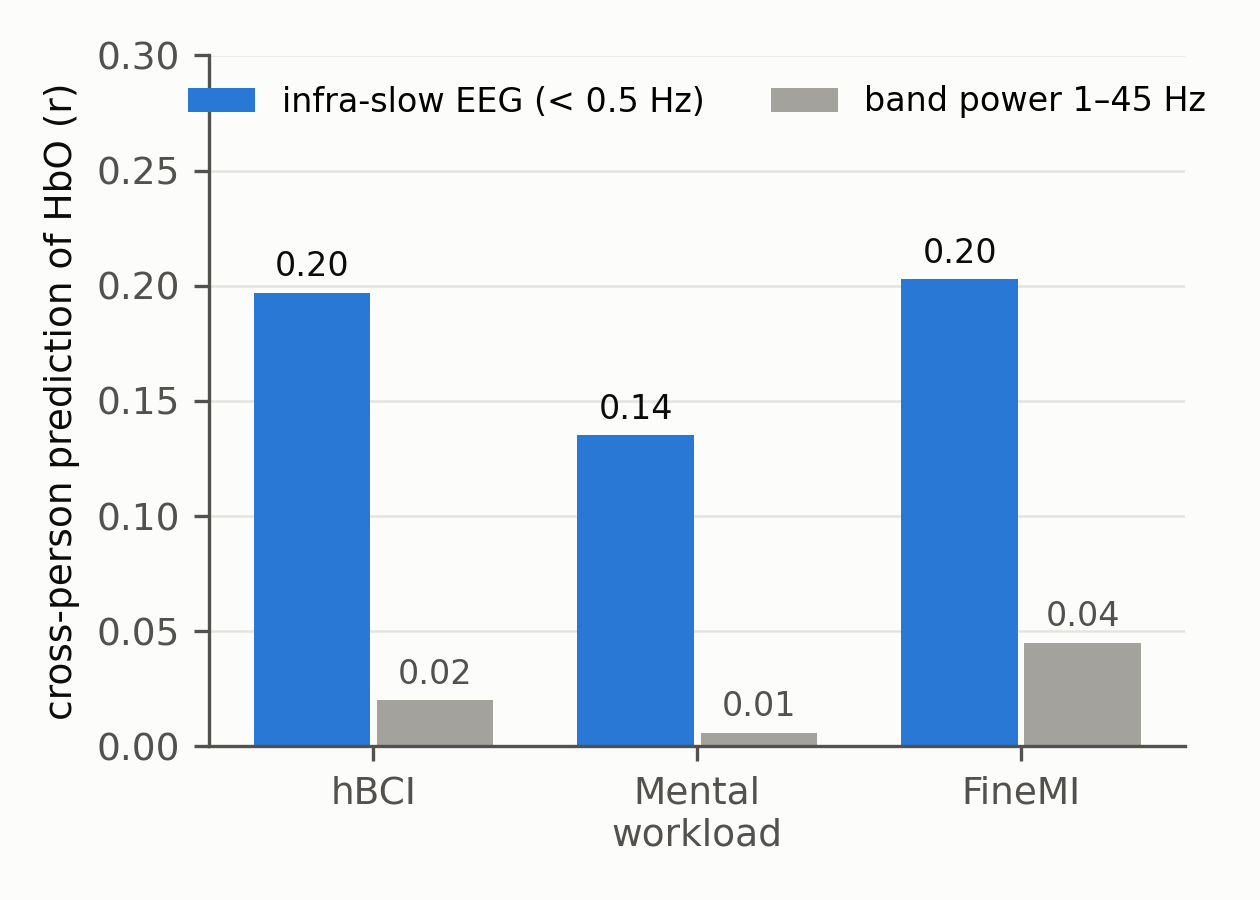

In [3]:
mw, fm = J("replication_results.json"), J("replication_finemi_results.json")
ps = J("person_specific_results_runs.json")["slow"]
def row(name, d):
    a = d["R1"]
    return [name, f"{a['slow_lt0.5']['r_subject']:.3f} {ci(*a['slow_lt0.5']['ci'])}", f"{a['bandpower_1-45']['r_subject']:.3f}",
            f"{a['eog_slow_lt0.5']['r_subject']:.3f}", f"{d['R3']['HbO_local']['r_subject']:.3f}", f"{d['R2']['slow_lt0.5']['identification']:.0%}"]
table([["hBCI (FINAL_PLAN T1, T2, T3)", "0.197 (ridge); 0.155 (deep)", "≈0.02", "14% of all-EEG score", "0.07–0.08", f"{ps['identification']:.0%}"],
       row("Mental workload", mw), row("FineMI", fm)],
      ["Cohort", "Slow EEG &lt; 0.5 Hz", "Band power 1–45 Hz", "EOG", "Local HbO", "Person identification"])
fig("fig1_slow_band", 420)

## Claim 1: one EEG space for fNIRS and fMRI

In [4]:
c1h = J("claim1_fresh_hbci_results.json")
rows = []
for n, d in (("Mental workload (primary)", c1m), ("FineMI", c1f), ("hBCI", c1h)):
    f, g = d["fnirs"]["joint"], d["fmri"]["joint"]
    rows.append([n, f"{f['r_subject']:.3f} {ci(f['ci_low'], f['ci_high'])}", f"{g['r_subject']:.3f} {ci(g['ci_low'], g['ci_high'])}",
                 f"{d['fnirs_joint_minus_specific']['ci90'][0]:+.3f}", f"{d['p31_joint_minus_shuffled_ci95']['mean']:+.4f}", "yes" if d["claim1_shared_space_holds"] else "no"])
table(rows, ["fNIRS cohort", "fNIRS r", "fMRI r", "Cost to fNIRS, 90% CI low (margin −0.02)", "Joint − shuffled fMRI", "Shared space holds"])

fNIRS cohort,fNIRS r,fMRI r,"Cost to fNIRS, 90% CI low (margin −0.02)",Joint − shuffled fMRI,Shared space holds
Mental workload (primary),"0.123 [+0.080, +0.169]","0.068 [+0.043, +0.095]",-0.014,-0.0009,yes
FineMI,"0.180 [+0.141, +0.226]","0.063 [+0.039, +0.089]",+0.002,+0.0028,yes
hBCI,"0.178 [+0.140, +0.214]","0.068 [+0.043, +0.095]",+0.001,+0.0009,yes


## Claim 2: external validation

Same lab


Test,r,95% CI,p
"hBCI → MW, slow EEG",+0.205,"[+0.128, +0.285]",0.0002
"MW → hBCI, slow EEG",+0.177,"[+0.143, +0.211]",0.0001
"hBCI → MW, band-power kernel",+0.098,"[+0.071, +0.124]",—
"hBCI → MW, calibrated gain",+0.066,"[+0.028, +0.110]",—


Other lab: hBCI → FineMI, best first


Form,Value,95% CI,Outcome
"Band-power kernel, calibrated gain (P8.3)",+0.020,"[+0.004, +0.039]",nominal
"Alpha + beta kernel, calibrated gain (P9.3)",+0.015,"[-0.003, +0.035]",fail
"Slow EEG, calibrated gain (P6.2)",-0.000,"[-0.003, +0.003]",fail
"Slow EEG, window + montage (P6.1)",-0.010,"[-0.041, +0.021]",fail
"Slow EEG, plain",-0.023,"[-0.050, +0.004]",fail
"Slow EEG, detrend",-0.024,"[-0.051, +0.002]",fail
"Slow EEG, linked mastoids",-0.025,"[-0.055, +0.004]",fail
"Slow EEG, Euclidean alignment",-0.027,"[-0.054, +0.001]",fail
"Band-power kernel, frozen (P7.2)",-0.053,"[-0.071, -0.034]",fail (negative)
"CBSI target, frozen (P8.2)",-0.055,"[-0.081, -0.032]",fail (negative)


Why: kernels within and between labs


Diagnostic,r,95% CI
FineMI leave-one-person-out,+0.074,"[+0.047, +0.105]"
FineMI kernel → hBCI,-0.029,"[-0.056, -0.000]"
"Broadband power vs global HbO, hBCI",-0.038,"[-0.055, -0.022]"
"Broadband power vs global HbO, Mental workload",-0.035,"[-0.077, +0.008]"
"Broadband power vs global HbO, FineMI",+0.044,"[+0.023, +0.067]"


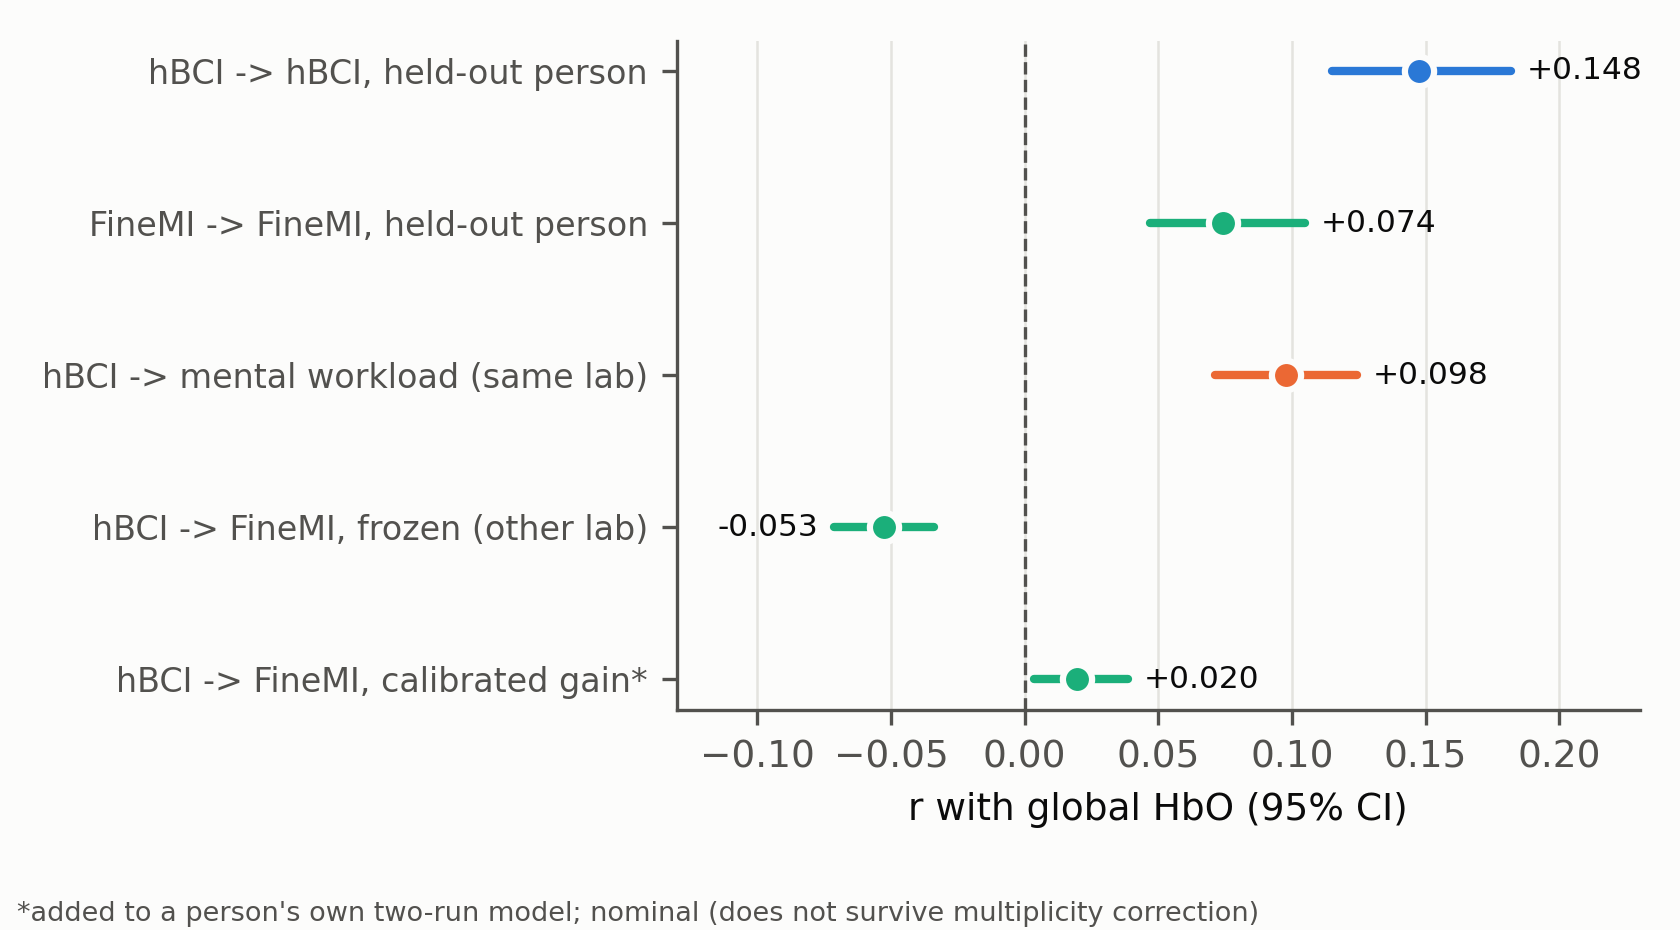

In [5]:
rev = J("external_claim2_results.json")["mental_workload_to_hbci"]
tr = J("nvc_transfer_results.json")
mwc = t2["calibrated | mental_workload"]
print("Same lab")
table([["hBCI → MW, slow EEG", f"{ext['r_subject']:+.3f}", ci(ext["ci_low"], ext["ci_high"]), f"{ext['p_signflip']:.4f}"],
       ["MW → hBCI, slow EEG", f"{rev['r_subject']:+.3f}", ci(rev["ci_low"], rev["ci_high"]), f"{rev['p_signflip']:.4f}"],
       ["hBCI → MW, band-power kernel", f"{tr['hbci_to_mental_workload']['mean_r']:+.3f}", ci(*tr["hbci_to_mental_workload"]["ci"]), "—"],
       ["hBCI → MW, calibrated gain", f"{mwc['diff']:+.3f}", ci(*mwc["ci"]), "—"]], ["Test", "r", "95% CI", "p"])
print("Other lab: hBCI → FineMI, best first")
h = J("harmonised_transfer_results.json")["hbci_to_finemi | primary: window + montage"]
base = [("Slow EEG, " + n, J(f)["hbci_to_finemi"]) for n, f in (("plain", "external_finemi_results.json"), ("detrend", "external_finemi_detrend_results.json"), ("linked mastoids", "external_finemi_lm_results.json"), ("Euclidean alignment", "external_finemi_ea_results.json"), ("hardware emulation", "external_finemi_hw_results.json"))]
b2 = J("nvc_bands_results.json")
ct = J("calibrated_transfer_results.json")["hbci_to_finemi"]
rows = [("Band-power kernel, calibrated gain (P8.3)", cal["diff"], cal["ci"], "nominal"),
        ("Alpha + beta kernel, calibrated gain (P9.3)", b2["calibrated | finemi | alpha+beta"]["diff"], b2["calibrated | finemi | alpha+beta"]["ci"], "fail"),
        ("Slow EEG, calibrated gain (P6.2)", ct["diff"], ct["ci"], "fail"),
        ("Slow EEG, window + montage (P6.1)", h["r_subject"], [h["ci_low"], h["ci_high"]], "fail")]
rows += [(n, v["r_subject"], [v["ci_low"], v["ci_high"]], "fail") for n, v in base]
rows += [("Band-power kernel, frozen (P7.2)", tr["hbci_to_finemi"]["mean_r"], tr["hbci_to_finemi"]["ci"], "fail (negative)"),
         ("CBSI target, frozen (P8.2)", t2["hbci_to_finemi | cbsi"]["mean_r"], t2["hbci_to_finemi | cbsi"]["ci"], "fail (negative)")]
table([[n, f"{m:+.3f}", ci(*c), v] for n, m, c, v in sorted(rows, key=lambda x: -x[1])], ["Form", "Value", "95% CI", "Outcome"])
print("Why: kernels within and between labs")
ld = J("nvc_labdiff_results.json")
table([["FineMI leave-one-person-out", f"{b2['lopo | finemi']['mean_r']:+.3f}", ci(*b2["lopo | finemi"]["ci"])],
       ["FineMI kernel → hBCI", f"{ld['finemi_to_hbci']['mean_r']:+.3f}", ci(*ld["finemi_to_hbci"]["ci"])]] +
      [[f"Broadband power vs global HbO, {COH[c]}", f"{ld['broadband | ' + c]['mean_r']:+.3f}", ci(*ld["broadband | " + c]["ci"])] for c in COH], ["Diagnostic", "r", "95% CI"])
fig("fig4_kernel_transfer", 560)

## Claim 3: coupling and delay

Cohort,Beat null,Median delay,Peak local r,"Kernel p, raw","Kernel p, task removed","Delay repeats, raw","Delay repeats, task removed"
hBCI,100%,+6.0 s,0.191,5.6e-09,4.7e-08,66% vs 29% (p 0.0003),69% vs 30% (p 0.0001)
Mental workload,81%,+4.0 s,0.135,9.1e-02,6.0e-03,23% vs 21% (p 0.4813),15% vs 20% (p 0.8046)
FineMI,89%,+3.0 s,0.053,3.3e-02,9.7e-04,17% vs 15% (p 0.5346),11% vs 15% (p 0.7870)


hBCI cut to other cohorts' recording length


Matched to,Delay repeats,p,Reproducible
mental_workload,34% vs 19%,0.0277,yes
finemi,66% vs 29%,0.0001,yes


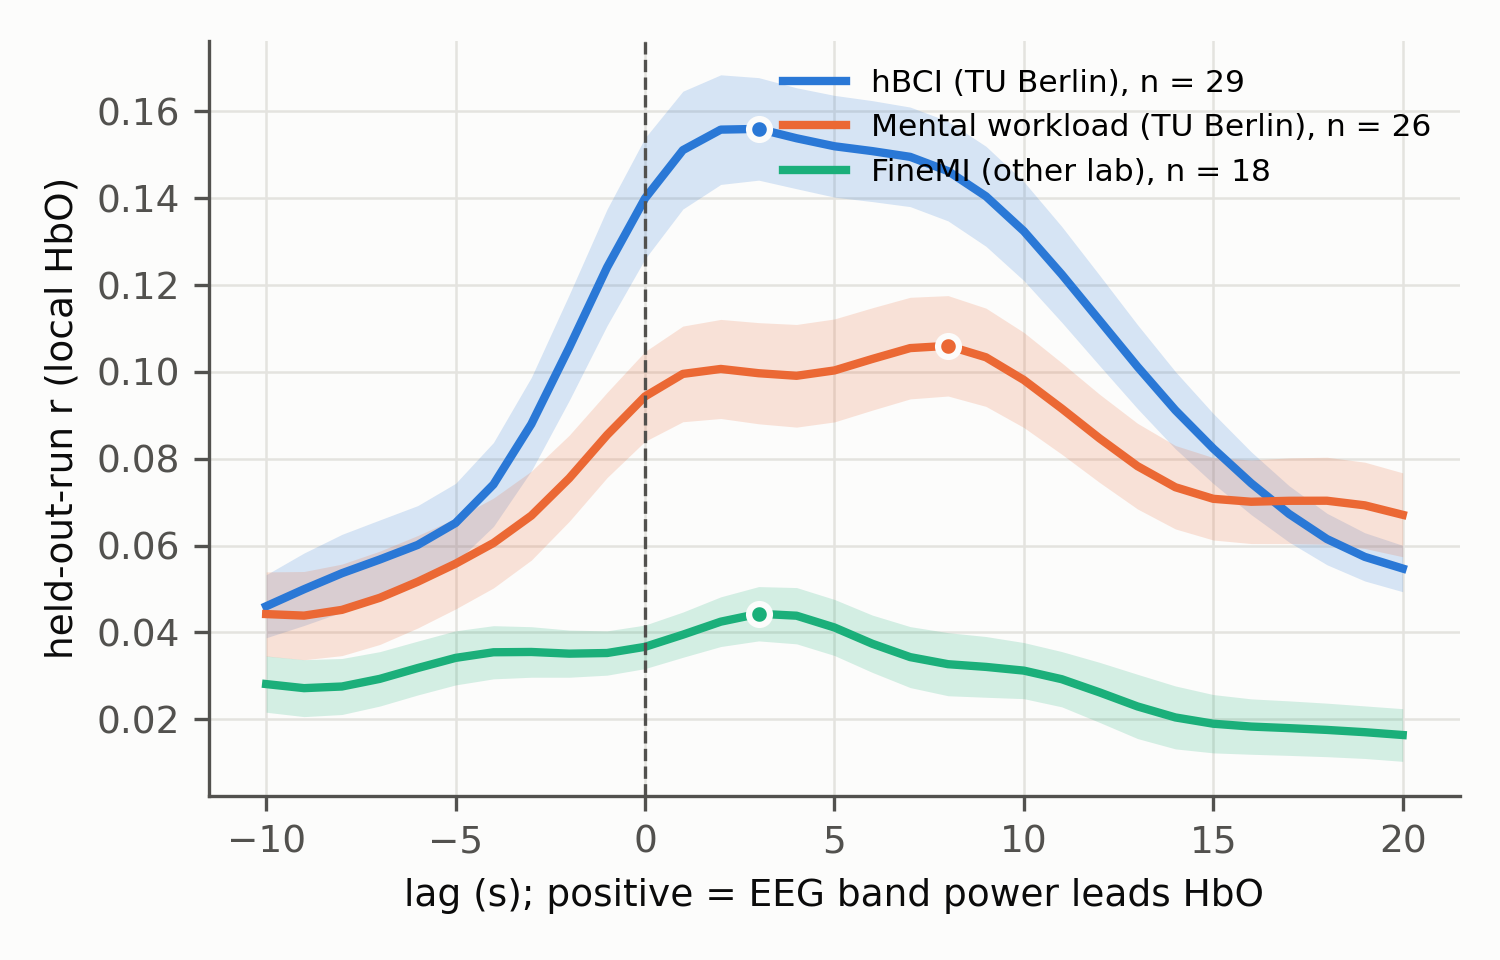

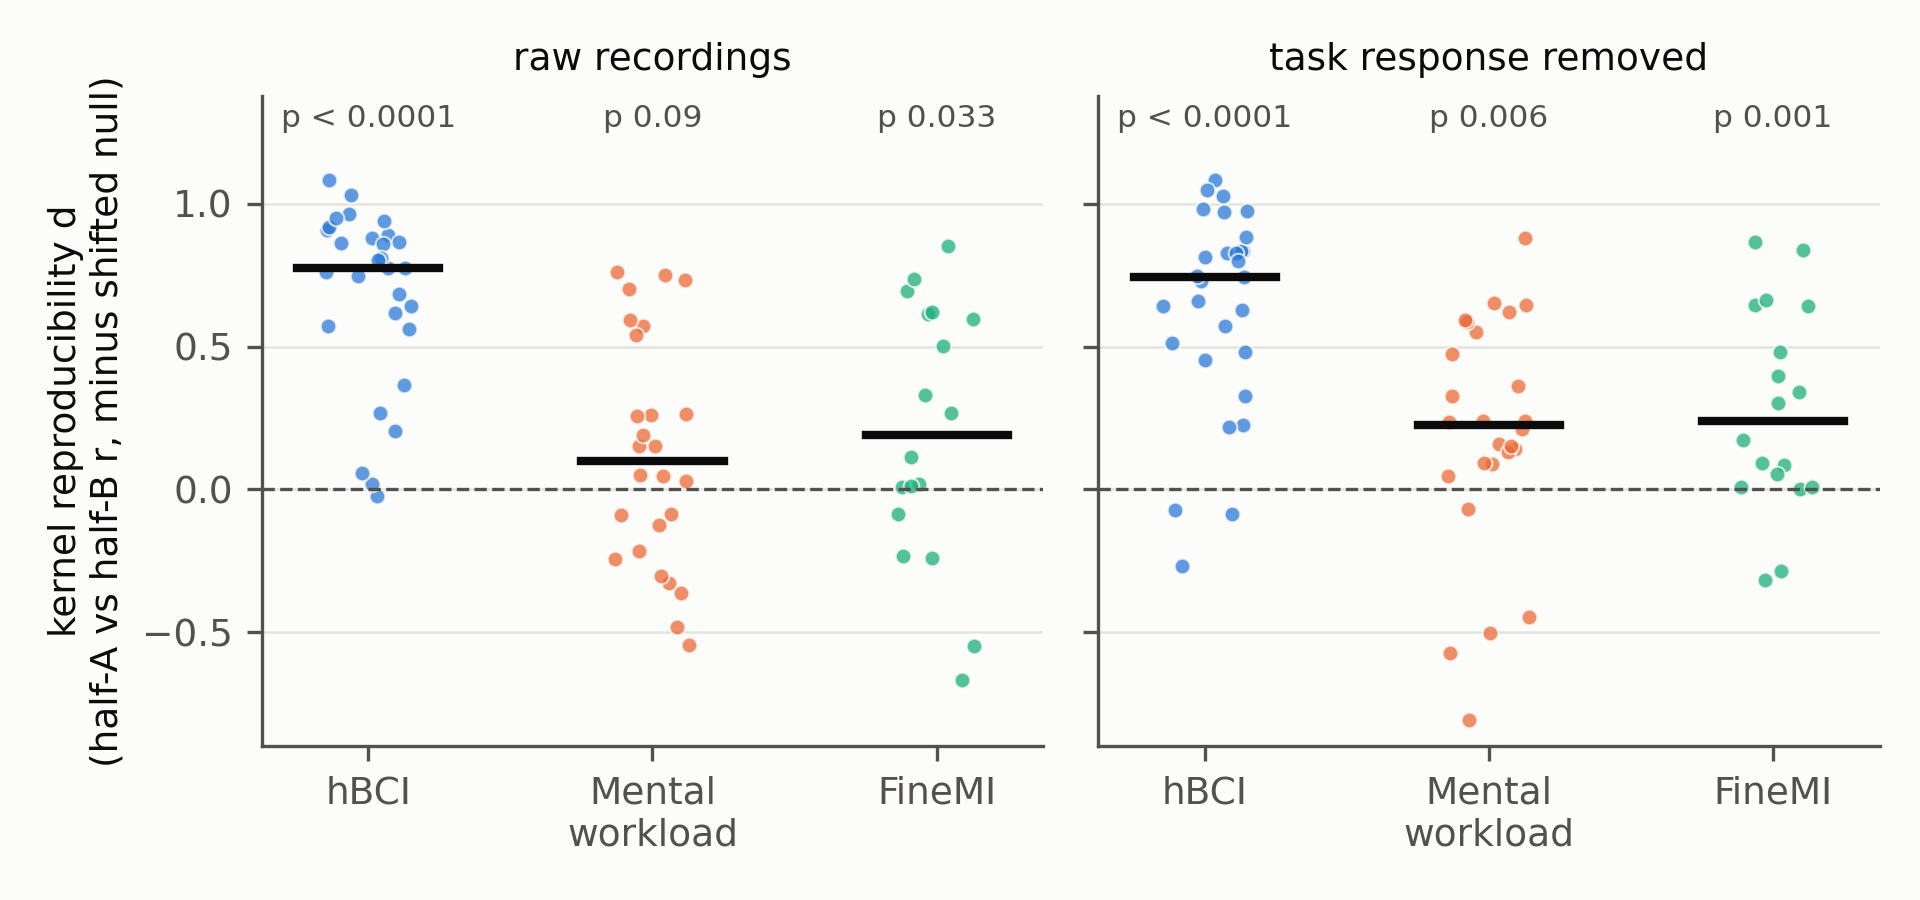

In [6]:
res, kr, kt = J("nvc_residual_results.json"), J("nvc_kernel_results.json"), J("nvc_kernel_resid_results.json")
rows = []
for c, n in COH.items():
    a, b = sm[f"{c} | raw"], sm[f"{c} | task removed"]
    rows.append([n, f"{bp[c]['frac_beating_null']:.0%}", f"{bp[c]['median_delay_s']:+.1f} s", f"{bp[c]['median_peak_r']:.3f}",
                 f"{kr[c]['wilcoxon_p_greater']:.1e}", f"{kt[c]['wilcoxon_p_greater']:.1e}",
                 f"{a['agree_2s']:.0%} vs {a['chance']:.0%} (p {a['p_agree']:.4f})", f"{b['agree_2s']:.0%} vs {b['chance']:.0%} (p {b['p_agree']:.4f})"])
table(rows, ["Cohort", "Beat null", "Median delay", "Peak local r", "Kernel p, raw", "Kernel p, task removed", "Delay repeats, raw", "Delay repeats, task removed"])
pw = J("nvc_power_results.json")
print("hBCI cut to other cohorts' recording length")
table([[k.replace("hbci matched to ", ""), f"{v['agree_2s']:.0%} vs {v['chance']:.0%}", f"{v['p_agree']:.4f}", "yes" if v["reproducible"] else "no"] for k, v in pw.items() if k.startswith("hbci matched")],
      ["Matched to", "Delay repeats", "p", "Reproducible"])
fig("fig2_coupling_lag", 520); fig("fig3_kernel_repro", 640)

## Claim 4: downstream EEG-only task

In [7]:
d = J("downstream_repr_nlab0_results.json")
table([[k, f"{v['mean_acc']['V']:.3f}", f"{v['mean_acc']['PC']:.3f}", f"{v['mean_acc']['Rp']:.3f}", f"{v['chance']:.3f}", "pass" if v["pass"] else "fail"] for k, v in d.items()],
      ["Task", "Virtual haemodynamics", "PCA", "Random projection", "Chance", "Rule"])

Task,Virtual haemodynamics,PCA,Random projection,Chance,Rule
hbci_MI_left_right (primary),0.697,0.760,0.707,0.500,fail
hbci_MA_vs_rest,0.675,0.668,0.636,0.500,fail
mw_nback_0_2_3,0.413,0.453,0.423,0.333,fail
finemi_8class,0.153,0.161,0.143,0.125,fail


## Claim 5 and deployment: two calibration runs

Cohort,"Gain, raw HbO","Gain, local HbO",Person reliability ρ,"ρ, local",Trial reliability
hBCI,"+0.176 [+0.135, +0.218]","+0.103 [+0.074, +0.136]","0.68 [+0.370, +0.865]",0.58,fail
Mental workload,"+0.059 [+0.025, +0.099]","+0.031 [+0.013, +0.052]","0.56 [+0.221, +0.783]",0.61,pass
FineMI,"+0.067 [+0.033, +0.112]","+0.041 [+0.014, +0.079]","0.90 [+0.689, +0.971]",0.84,fail


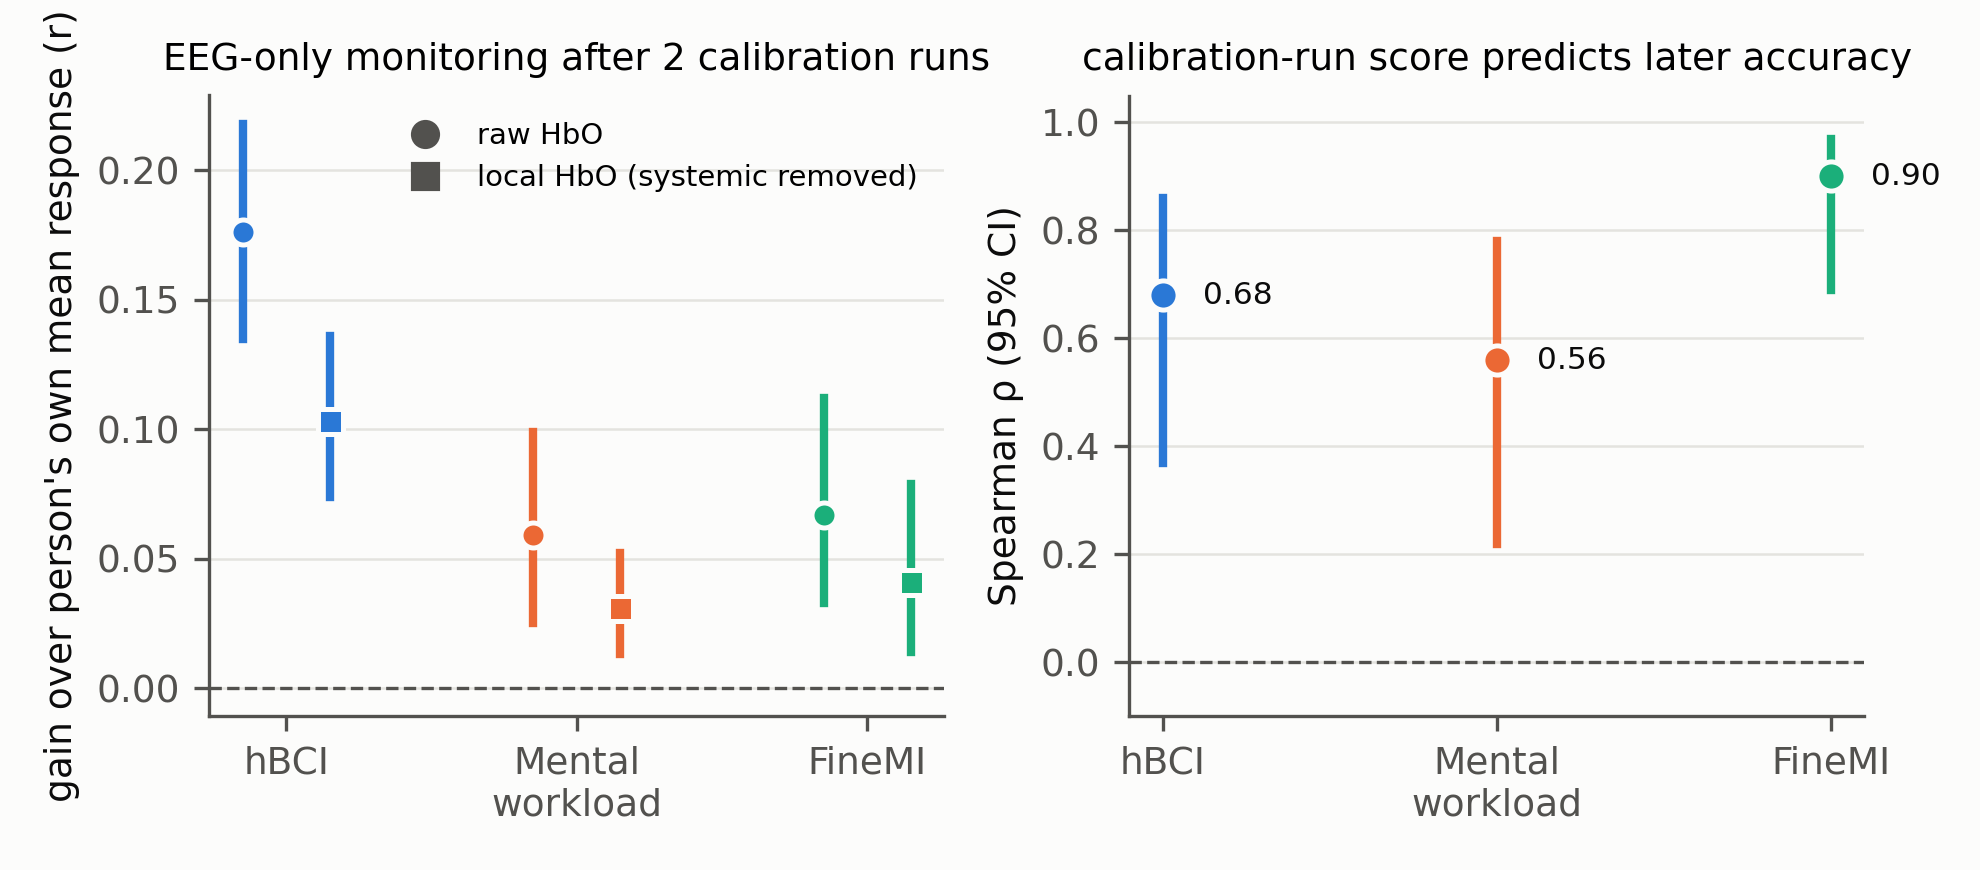

In [8]:
g, gl = J("calibration_results.json"), J("calibration_results_local.json")
loc = J("calib_reliability_local_results.json")
trl = J("trial_reliability_results.json")
rows = []
for c, n in COH.items():
    a, b = g[c]["gains"]["k2_personal_minus_baseline"], gl[c]["gains"]["k2_personal_minus_baseline"]
    rows.append([n, f"{a['mean']:+.3f} {ci(*a['ci'])}", f"{b['mean']:+.3f} {ci(*b['ci'])}",
                 f"{rel[c]['spearman_score_vs_minus_error']:.2f} {ci(*rel[c]['ci95'])}", f"{loc[c]['spearman_score_vs_minus_error']:.2f}", "pass" if trl[c]["passes"] else "fail"])
table(rows, ["Cohort", "Gain, raw HbO", "Gain, local HbO", "Person reliability ρ", "ρ, local", "Trial reliability"])
fig("fig5_deployment_reliability", 640)

## What survives correction for all attempts

In [9]:
from_attempts = {"Claim 1": 8, "Claim 2 same lab": 3, "Claim 2 other lab": 16, "Claim 3": 13, "Claim 5": 4}
p83 = signflip([v["personal_plus_external"] - v["personal"] for v in cal["people"].values()])
items = [("Claim 1", "Shared space predicts fMRI", c1m["fmri"]["joint"]["p_signflip"]),
         ("Claim 2 same lab", "hBCI → MW, slow EEG", ext["p_signflip"]),
         ("Claim 2 other lab", "hBCI → FineMI, calibrated (P8.3)", p83),
         ("Claim 3", "hBCI kernel repeats", kr["hbci"]["wilcoxon_p_greater"]),
         ("Claim 3", "hBCI delay repeats", sm["hbci | raw"]["p_agree"]),
         ("Claim 3", "FineMI kernel, task removed", kt["finemi"]["wilcoxon_p_greater"]),
         ("Claim 3", "MW kernel, task removed", kt["mental_workload"]["wilcoxon_p_greater"]),
         ("Claim 3", "FineMI kernel, raw", kr["finemi"]["wilcoxon_p_greater"])]
items += [("Claim 5", f"Reliability, {COH[c]}", spearman_p(rel[c]["spearman_score_vs_minus_error"], rel[c]["n"])) for c in COH]
rows = []
for fam, name, p in items:
    n = from_attempts[fam]
    a, b = 0.05 / n, 0.05 / (n * 3)
    rows.append([fam, name, f"{p:.1e}", n, f"{a:.4f}", "yes" if p < a else "<b>no</b>", "yes" if p < b else "<b>no</b>"])
table(rows, ["Family", "Result", "p", "Attempts", "α", "Survives", "Survives if cohorts counted too (×3)"])

Family,Result,p,Attempts,α,Survives,Survives if cohorts counted too (×3)
Claim 1,Shared space predicts fMRI,1.0e-04,8,0.0063,yes,yes
Claim 2 same lab,"hBCI → MW, slow EEG",2.0e-04,3,0.0167,yes,yes
Claim 2 other lab,"hBCI → FineMI, calibrated (P8.3)",1.7e-02,16,0.0031,no,no
Claim 3,hBCI kernel repeats,5.6e-09,13,0.0038,yes,yes
Claim 3,hBCI delay repeats,3.0e-04,13,0.0038,yes,yes
Claim 3,"FineMI kernel, task removed",9.7e-04,13,0.0038,yes,yes
Claim 3,"MW kernel, task removed",6.0e-03,13,0.0038,no,no
Claim 3,"FineMI kernel, raw",3.3e-02,13,0.0038,no,no
Claim 5,"Reliability, hBCI",5.0e-05,4,0.0125,yes,yes
Claim 5,"Reliability, Mental workload",3.1e-03,4,0.0125,yes,yes


## Latest round (P10)

In [10]:
f = R / "nvc_broadband_results.json"
if not f.exists():
    print("P10.1 still running: no result yet.")
else:
    d = J("nvc_broadband_results.json")
    table([[k.split(" | ")[0].replace("hbci_to_", "hBCI → "), k.split(" | ")[1], f"{d[k]['mean_r']:+.3f}", ci(*d[k]["ci"]), f"{d[k]['frac_beating_null']:.0%}", "pass" if d[k]["pass"] else "fail"]
           for k in d if k.startswith("hbci_to_")], ["Direction", "Kernel", "r", "95% CI", "Beat null", "P7.2 rule"])
    table([[k, f"{v['diff']:+.3f}", ci(*v["ci"]), f"{v.get('signflip_p', v.get('signflip_p_removed')):.4f}"] for k, v in d.items() if k.startswith(("paired", "calibrated"))], ["Test", "Diff", "95% CI", "Sign-flip p"])
f = R / "nvc_snr_results.json"
if not f.exists():
    print("P10.2 still running: no result yet.")
else:
    d = J("nvc_snr_results.json")
    table([[k, f"{v['agree_2s']:.0%} vs {v['chance']:.0%}", f"{v['p_agree']:.4f}", "yes" if v["reproducible"] else "no"] for k, v in d.items() if k.startswith("hbci at")], ["Level", "Delay repeats", "p", "Reproducible"])

P10.1 still running: no result yet.
P10.2 still running: no result yet.
